In [1]:
# import libraries for data analysis and visualization


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
# 2- Load the dataset

In [4]:
# Load the cleaned CSV dataset
data = pd.read_csv("Sales_data_cleaned.csv")
df = pd.DataFrame(data)
# Display the first five records
df.head()

,Order_ID,Order_Date,Customer_ID,Customer_Name,Age,Gender,City,Product,Category,Quantity,Unit_Price,Total_Sales
0,ORD100002,2025-02-25,CUST5529,Customer_227,30.0,Female,Bengaluru,Rice,Grocery,7,2829.77,19808.39
1,ORD100003,2025-10-14,CUST3127,Customer_182,63.0,Male,Bengaluru,Book,Education,5,27906.16,139530.80
2,ORD100004,2025-05-13,CUST8887,Customer_487,62.0,Female,Bengaluru,Book,Education,8,37491.06,299928.48
3,ORD100005,2025-12-02,CUST2515,Customer_470,65.0,Female,Kolkata,Mobile,Electronics,9,28541.36,256872.24
4,ORD100006,2025-11-20,CUST4796,Customer_380,44.0,Male,Bengaluru,Rice,Grocery,10,14036.59,140365.90


In [5]:
# 3. Check dataset dimensions

In [6]:
# Display number of rows and columns
print("Dataset shape:", df.shape)
# Display column names
print("\n Column Names:")
print(df.columns)

Dataset shape: (1000, 12)

 Column Names:
Index(['Order_ID', 'Order_Date', 'Customer_ID', 'Customer_Name', 'Age',
       'Gender', 'City', 'Product', 'Category', 'Quantity', 'Unit_Price',
       'Total_Sales'],
      dtype='object')


In [7]:
# 4. Check data types of all columns
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Order_ID       1000 non-null   object 
 1   Order_Date     1000 non-null   object 
 2   Customer_ID    1000 non-null   object 
 3   Customer_Name  1000 non-null   object 
 4   Age            1000 non-null   float64
 5   Gender         1000 non-null   object 
 6   City           1000 non-null   object 
 7   Product        1000 non-null   object 
 8   Category       1000 non-null   object 
 9   Quantity       1000 non-null   int64  
 10  Unit_Price     1000 non-null   float64
 11  Total_Sales    1000 non-null   float64
dtypes: float64(3), int64(1), object(8)
memory usage: 93.9+ KB


# Convert Order_Date into datetime

In [8]:
# Convert Order_Date from object to datetime

df["Order_Date"] = pd.to_datetime(
    df["Order_Date"],
    format="%Y-%m-%d",
    errors="coerce"
)

# Check the updated data types
print(df.dtypes)

# Understand the code
# - pd.to_datetime() converts values into date format.
# - format="%Y-%m-%d" tells Pandas the date pattern is Year-Month-Day.
# - errors="coerce" converts invalid date values into NaT (Not a Time).


Order_ID                 object
Order_Date       datetime64[ns]
Customer_ID              object
Customer_Name            object
Age                     float64
Gender                   object
City                     object
Product                  object
Category                 object
Quantity                  int64
Unit_Price              float64
Total_Sales             float64
dtype: object


In [9]:
# Verify the conversion
print("Order_Date datatype:", df["Order_Date"].dtype)

print("\nMissing dates:", df["Order_Date"].isna().sum())

print("\nFirst five dates:")
print(df["Order_Date"].head())

Order_Date datatype: datetime64[ns]

Missing dates: 0

First five dates:
0   2025-02-25
1   2025-10-14
2   2025-05-13
3   2025-12-02
4   2025-11-20
Name: Order_Date, dtype: datetime64[ns]


In [10]:
# Save the updated dataset
df.to_csv("sales_data_cleaned.csv", index=False)

print("Dataset updated successfully!")

Dataset updated successfully!


# step1 . Calculate descriptive statistics

In [11]:
# Calculate summary  statistics for  numericcal columns
df.describe()

,Order_Date,Age,Quantity,Unit_Price,Total_Sales
count,1000,1000.000000,1000.000000,1000.000000,1000.000000
mean,2025-07-03 11:19:40.800000,41.353000,5.435000,25486.783410,139399.439650
min,2025-01-01 00:00:00,18.000000,1.000000,145.780000,437.340000
25%,2025-03-30 18:00:00,30.000000,3.000000,13895.722500,47066.632500
50%,2025-07-01 00:00:00,41.000000,5.000000,25398.740000,108594.025000
75%,2025-10-07 06:00:00,53.000000,8.000000,37512.382500,203722.882500
max,2026-01-01 00:00:00,65.000000,10.000000,49997.530000,493677.500000
std,NaN,13.683626,2.838632,14179.402361,114100.051546


# Step 2: Descriptive statistics for categorical columns
numerical statistics are not suitable for columns such as Product, city, Gender and category.

In [12]:
# Summary statistics for categorical columns
df.describe(include="object")

,Order_ID,Customer_ID,Customer_Name,Gender,City,Product,Category
count,1000,1000,1000,1000,1000,1000,1000
unique,992,947,425,2,9,6,5
top,ORD100050,CUST2515,Customer_359,Male,Patna,Mobile,Electronics
freq,9,3,8,511,135,184,354


In [13]:
# Find all rows having repeated Order_ID values
repeated_rows = df[
    df["Order_ID"].duplicated(keep=False)
]

# Display those rows
repeated_rows.sort_values("Order_ID")

,Order_ID,Order_Date,Customer_ID,Customer_Name,Age,Gender,City,Product,Category,Quantity,Unit_Price,Total_Sales
48,ORD100050,2025-10-03,CUST5523,Customer_432,41.0,Male,Pune,Chair,Furniture,9,30834.87,277513.83
118,ORD100050,2025-01-22,CUST3194,Customer_114,34.0,Male,Kolkata,Book,Education,2,25795.55,51591.10
238,ORD100050,2025-03-01,CUST8467,Customer_104,23.0,Male,Bengaluru,Book,Education,3,2860.83,8582.49
358,ORD100050,2025-02-11,CUST6467,Customer_181,24.0,Female,Pune,Rice,Grocery,7,45480.39,318362.73
478,ORD100050,2025-11-22,CUST8225,Customer_468,64.0,Male,Bengaluru,Rice,Grocery,8,38957.59,311660.72
598,ORD100050,2025-02-21,CUST8859,Customer_53,41.0,Male,Unknown,Laptop,Electronics,7,20144.84,141013.88
718,ORD100050,2025-11-06,CUST7824,Customer_190,31.0,Female,Mumbai,Rice,Grocery,4,42642.59,170570.36
838,ORD100050,2025-08-03,CUST5585,Customer_289,35.0,Male,Kolkata,Chair,Furniture,9,28747.47,258727.23
958,ORD100050,2025-02-09,CUST7188,Customer_89,62.0,Male,Bengaluru,Mobile,Electronics,1,34619.77,34619.77


In [14]:
print("Complete duplicate rows:", df.duplicated().sum())

Complete duplicate rows: 0


In [15]:
# Count occurrences of each Order ID
order_counts = df["Order_ID"].value_counts()

# Display all repeated Order IDs
print(order_counts[order_counts > 1])

Order_ID
ORD100050    9
Name: count, dtype: int64


In [16]:
# Check total number of unique Order IDs
print("Total records:", len(df))
print("Unique Order IDs:", df["Order_ID"].nunique())
print("Repeated Order IDs:", (order_counts > 1).sum())

Total records: 1000
Unique Order IDs: 992
Repeated Order IDs: 1


In [17]:
# Check unique values in important columns

print("Unique Customer IDs:", df["Customer_ID"].nunique())

print("Unique Customer Names:", df["Customer_Name"].nunique())

print("Unique Products:", df["Product"].nunique())

print("Unique Categories:", df["Category"].nunique())

print("Unique Cities:", df["City"].nunique())

Unique Customer IDs: 947
Unique Customer Names: 425
Unique Products: 6
Unique Categories: 5
Unique Cities: 9


In [18]:
# Count different names associated with each Customer ID

customer_name_check = (
    df.groupby("Customer_ID")["Customer_Name"]
    .nunique()
)

# Find Customer IDs associated with multiple names

inconsistent_customers = customer_name_check[
    customer_name_check > 1
]

print("Customer IDs with multiple names:")
print(inconsistent_customers)

Customer IDs with multiple names:
Customer_ID
CUST1463    2
CUST1994    2
CUST1997    2
CUST2515    3
CUST2794    2
CUST2870    2
CUST3001    2
CUST3006    2
CUST3366    2
CUST3508    2
CUST3689    2
CUST3730    2
CUST3763    2
CUST3773    2
CUST4041    2
CUST4137    2
CUST4706    2
CUST4756    2
CUST4996    2
CUST5363    2
CUST5806    2
CUST6067    2
CUST6082    2
CUST6111    2
CUST6345    2
CUST6407    2
CUST6532    2
CUST6704    2
CUST6845    2
CUST7026    2
CUST7188    2
CUST7317    2
CUST7374    2
CUST7568    2
CUST7824    2
CUST8053    2
CUST8708    2
CUST9081    2
CUST9089    2
CUST9209    2
CUST9287    2
CUST9307    2
CUST9381    2
CUST9421    2
CUST9458    2
CUST9465    2
CUST9469    2
CUST9510    2
CUST9645    2
CUST9693    2
CUST9942    2
CUST9966    2
Name: Customer_Name, dtype: int64


In [19]:
# Display all records for CUST2515

df[df["Customer_ID"] == "CUST2515"][
    ["Customer_ID", "Customer_Name", "Age", "Gender", "City"]
]

,Customer_ID,Customer_Name,Age,Gender,City
3,CUST2515,Customer_470,65.0,Female,Kolkata
540,CUST2515,Customer_74,26.0,Female,Patna
554,CUST2515,Customer_219,21.0,Male,Hyderabad


In [20]:
# Count total records belonging to inconsistent Customer IDs

affected_rows = df[
    df["Customer_ID"].isin(inconsistent_customers.index)
]

print("Affected records:", len(affected_rows))
print("Affected percentage:",
      round(len(affected_rows) / len(df) * 100, 2), "%")

Affected records: 105
Affected percentage: 10.5 %


In [21]:
# Check whether one Customer_Name is associated
# with multiple Customer_IDs

name_id_check = (
    df.groupby("Customer_Name")["Customer_ID"]
    .nunique()
)

inconsistent_names = name_id_check[name_id_check > 1]

print("Customer names linked to multiple IDs:")
print(inconsistent_names)

print("Total inconsistent names:", len(inconsistent_names))

Customer names linked to multiple IDs:
Customer_Name
Customer_1      4
Customer_10     2
Customer_101    2
Customer_102    2
Customer_103    6
               ..
Customer_94     2
Customer_96     3
Customer_97     2
Customer_98     5
Customer_99     2
Name: Customer_ID, Length: 294, dtype: int64
Total inconsistent names: 294


In [22]:
# Find records belonging to names associated with multiple IDs

affected_name_rows = df[
    df["Customer_Name"].isin(inconsistent_names.index)
]

print("Affected records:", len(affected_name_rows))

print(
    "Affected percentage:",
    round(len(affected_name_rows) / len(df) * 100, 2),
    "%"
)

Affected records: 869
Affected percentage: 86.9 %


In [23]:
# Display records for Customer_103

df[df["Customer_Name"] == "Customer_103"][
    ["Customer_ID", "Customer_Name", "Age", "Gender", "City"]
]


,Customer_ID,Customer_Name,Age,Gender,City
18,CUST5806,Customer_103,57.0,Female,Mumbai
109,CUST9882,Customer_103,28.0,Female,Kolkata
294,CUST8294,Customer_103,30.0,Female,Hyderabad
344,CUST2051,Customer_103,31.0,Male,Bengaluru
429,CUST4215,Customer_103,28.0,Male,Delhi
661,CUST1673,Customer_103,18.0,Male,Gaya


# Final task 2


In [24]:
# step 1: Calculate descriptive statistics
# Display descriptive statistics for numerical columns

df.describe()

,Order_Date,Age,Quantity,Unit_Price,Total_Sales
count,1000,1000.000000,1000.000000,1000.000000,1000.000000
mean,2025-07-03 11:19:40.800000,41.353000,5.435000,25486.783410,139399.439650
min,2025-01-01 00:00:00,18.000000,1.000000,145.780000,437.340000
25%,2025-03-30 18:00:00,30.000000,3.000000,13895.722500,47066.632500
50%,2025-07-01 00:00:00,41.000000,5.000000,25398.740000,108594.025000
75%,2025-10-07 06:00:00,53.000000,8.000000,37512.382500,203722.882500
max,2026-01-01 00:00:00,65.000000,10.000000,49997.530000,493677.500000
std,NaN,13.683626,2.838632,14179.402361,114100.051546


In [25]:
# Verify the date range
# Find the earliest and latest order dates

print("Earliest Order Date:", df["Order_Date"].min())

print("Latest Order Date:", df["Order_Date"].max())

# Display records from January 2026

df[df["Order_Date"] >= "2026-01-01"][
    ["Order_ID", "Order_Date", "Product", "Total_Sales"]
]

Earliest Order Date: 2025-01-01 00:00:00
Latest Order Date: 2026-01-01 00:00:00


,Order_ID,Order_Date,Product,Total_Sales
77,ORD100079,2026-01-01,Rice,35862.34
163,ORD100165,2026-01-01,Rice,141200.44
305,ORD100307,2026-01-01,Rice,187087.76
572,ORD100574,2026-01-01,Mobile,98080.92
794,ORD100796,2026-01-01,Shoes,347158.53


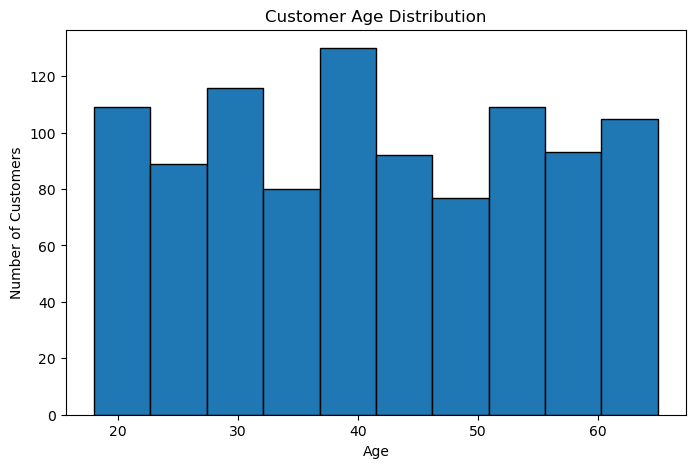

In [26]:
# Histogram
# Create a figure
plt.figure(figsize=(8, 5))

# Create histogram for customer age
plt.hist(df["Age"], bins=10, edgecolor="black")

# Add chart title and labels
plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

# Display the chart
plt.show()

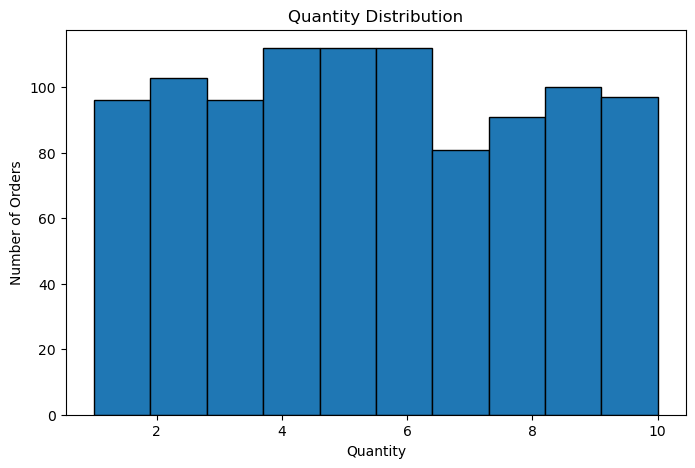

In [27]:
# Quantity distribution histogram
plt.figure(figsize=(8, 5))

plt.hist(df["Quantity"], bins=10, edgecolor="black")

plt.title("Quantity Distribution")
plt.xlabel("Quantity")
plt.ylabel("Number of Orders")

plt.show()

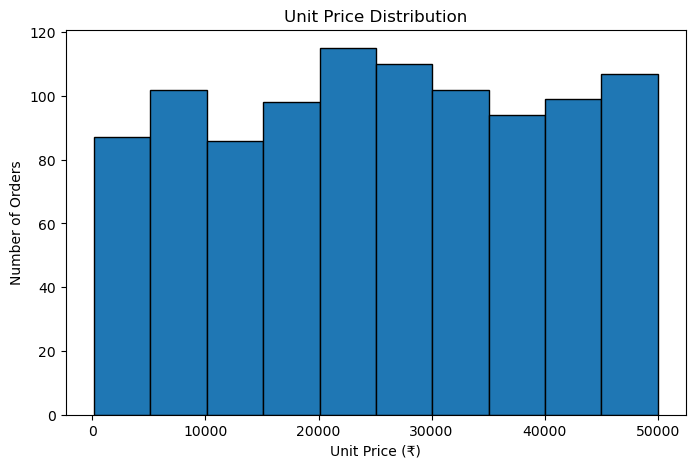

In [28]:
# Unit Price Distribution
plt.figure(figsize=(8, 5))

plt.hist(df["Unit_Price"], bins=10, edgecolor="black")

plt.title("Unit Price Distribution")
plt.xlabel("Unit Price (₹)")
plt.ylabel("Number of Orders")

plt.show()

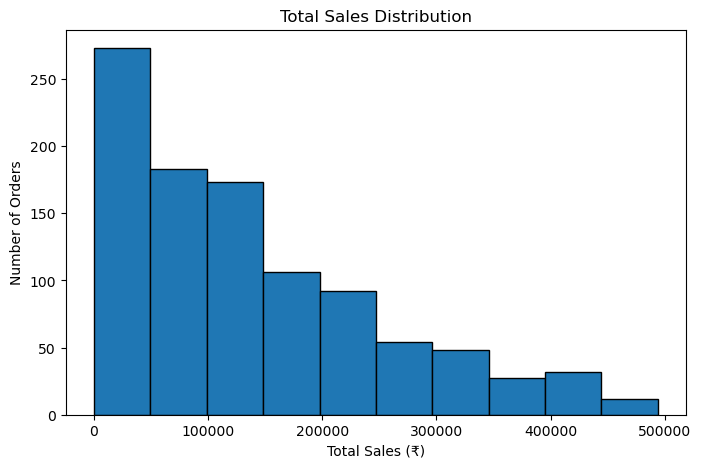

In [29]:
# Total Sales Distribution
plt.figure(figsize=(8, 5))

plt.hist(df["Total_Sales"], bins=10, edgecolor="black")

plt.title("Total Sales Distribution")
plt.xlabel("Total Sales (₹)")
plt.ylabel("Number of Orders")

plt.show()

# Gender Distribution - Bar chart
Understand the distribution of customers by gender.

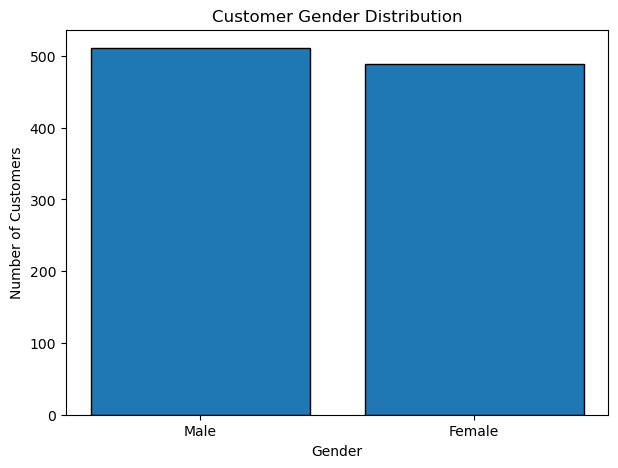

In [30]:
gender_counts = df["Gender"].value_counts()

plt.figure(figsize=(7, 5))

plt.bar(gender_counts.index, gender_counts.values, edgecolor="black")

plt.title("Customer Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")

plt.show()

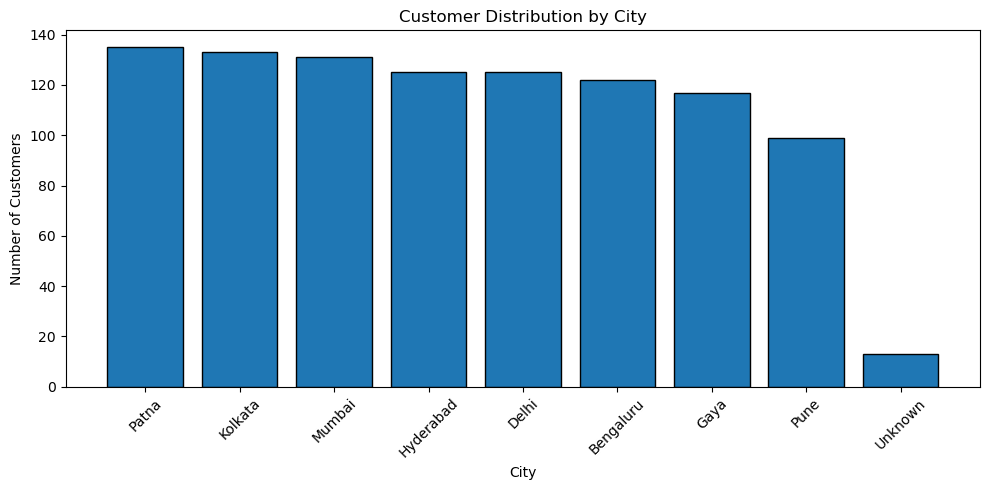

In [31]:
# City Distribution - bar chart
# Identify which cities contribute the most customer records in the dataset.

city_counts = df["City"].value_counts()

plt.figure(figsize=(10, 5))

plt.bar(city_counts.index, city_counts.values, edgecolor="black")

plt.title("Customer Distribution by City")
plt.xlabel("City")
plt.ylabel("Number of Customers")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

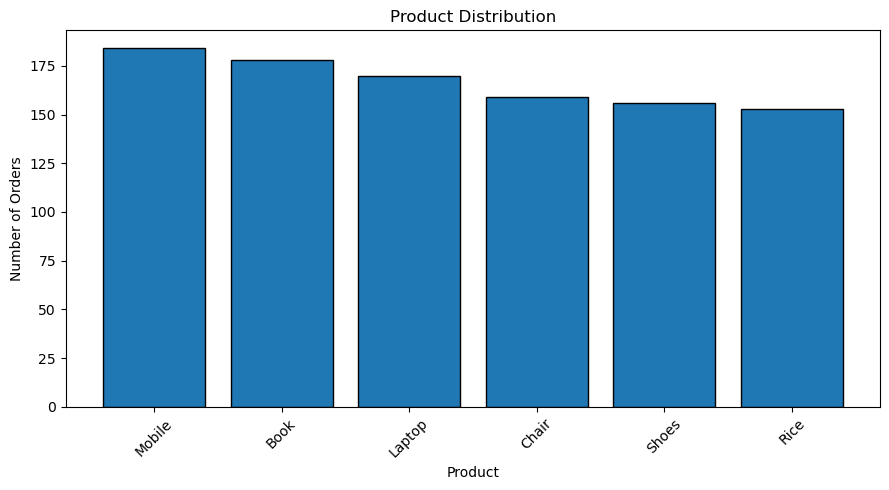

In [32]:
# 7: Product Distribution - Bar Chart
# Identify which products appear most frequently in the sales dataset.
product_counts = df["Product"].value_counts()

plt.figure(figsize=(9, 5))

plt.bar(product_counts.index, product_counts.values, edgecolor="black")

plt.title("Product Distribution")
plt.xlabel("Product")
plt.ylabel("Number of Orders")

plt.xticks(rotation=45) # rotates product names for readability.
plt.tight_layout() # prevents labels getting cut off.
plt.show()

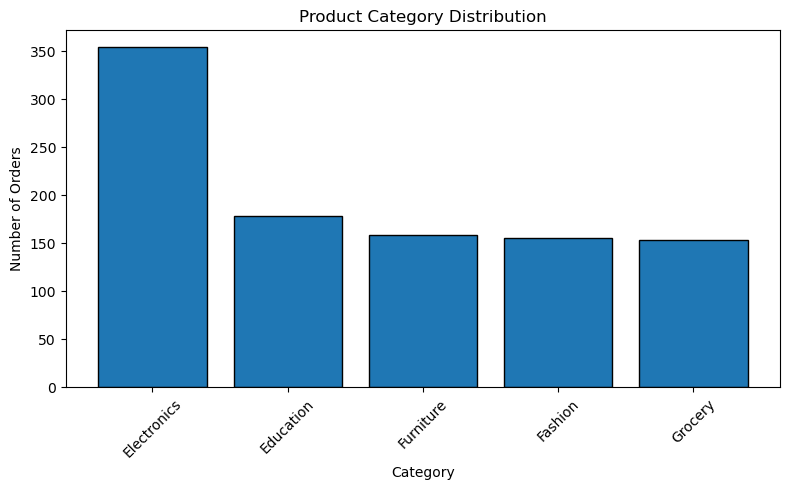

In [33]:
# Category Distribution - Bar Chart
# Understand how sales records are distributed across different product categories.
category_counts = df["Category"].value_counts()

plt.figure(figsize=(8, 5))

plt.bar(category_counts.index, category_counts.values, edgecolor="black")

plt.title("Product Category Distribution")
plt.xlabel("Category")
plt.ylabel("Number of Orders")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# SQL for Business Questions

In [34]:
import sqlite3
import pandas as pd

# Connect to the existing SQLite database
connection = sqlite3.connect("sales_analysis.db")

print("Database connected successfully!")

Database connected successfully!


In [35]:
import os
import sqlite3
import pandas as pd

print("Current folder:", os.getcwd())
print("Database path:", os.path.abspath("sales_analysis.db"))
print("Database exists:", os.path.exists("sales_analysis.db"))

Current folder: C:\Users\gauri\apnacollege-demo\Apexplanetinternship\Task-2 EDA and Business intelligence
Database path: C:\Users\gauri\apnacollege-demo\Apexplanetinternship\Task-2 EDA and Business intelligence\sales_analysis.db
Database exists: True


In [36]:
tables = pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type='table';",
    connection
)

print(tables)

Empty DataFrame
Columns: [name]
Index: []


In [37]:
# Step 1:  Check whether the CSV file is available
import os

print(os.path.exists("sales_data_cleaned.csv"))

True


In [38]:
# Load the cleaned dataset
df = pd.read_csv("sales_data_cleaned.csv")

# Connect to the database
connection = sqlite3.connect("sales_analysis.db")

# Create the sales table
df.to_sql("sales", connection, if_exists="replace", index=False)

print("Sales table created successfully!")

Sales table created successfully!


In [39]:
# 1 Verify the records
result = pd.read_sql_query(
    "SELECT COUNT(*) AS Total_Records FROM sales;",
    connection
)

print(result)

   Total_Records
0           1000


In [40]:
# Business Question 1: What is the total revenue generated by the business?
query = """
SELECT SUM(Total_Sales) AS Total_Revenue
FROM sales;
"""

result = pd.read_sql_query(query, connection)

print(result)
# Result is scientific notation. it represents approximately.


   Total_Revenue
0   1.393994e+08


In [41]:
# to display full amount
print("Total Revenue: ₹{:,.2f}".format(result["Total_Revenue"][0]))

Total Revenue: ₹139,399,439.65


In [42]:
# Business Question 2: Which product has the highest quantity sold?
# Why are we asking this?
query = """
SELECT
    Product,
    SUM(Quantity) AS Total_Quantity_Sold
FROM sales
GROUP BY Product
ORDER BY Total_Quantity_Sold DESC;
"""

result = pd.read_sql_query(query, connection)

print(result)

  Product  Total_Quantity_Sold
0  Mobile                 1008
1    Book                  977
2  Laptop                  970
3   Chair                  855
4    Rice                  826
5   Shoes                  799


In [43]:
# Business Question 3: Which city generates the highest total sales?
query = """
SELECT
    City,
    SUM(Total_Sales) AS Total_Sales
FROM sales
GROUP BY City
ORDER BY Total_Sales DESC;
"""

result = pd.read_sql_query(query, connection)

print(result)

        City  Total_Sales
0      Patna  19285966.89
1    Kolkata  18884349.57
2  Bengaluru  18773574.32
3     Mumbai  18757050.17
4  Hyderabad  17166766.87
5      Delhi  16097079.00
6       Pune  14513175.90
7       Gaya  14380859.39
8    Unknown   1540617.54


In [44]:
# Business Question 4: What is the average order value?
query = """
SELECT
    AVG(Total_Sales) AS Average_Order_Value
FROM sales;
"""

result = pd.read_sql_query(query, connection)

print(result)

   Average_Order_Value
0         139399.43965


In [45]:
# Business Question 5: Which product category generates the highest revenue?
query = """
SELECT
    Category,
    SUM(Total_Sales) AS Category_Revenue
FROM sales
GROUP BY Category
ORDER BY Category_Revenue DESC;
"""

result = pd.read_sql_query(query, connection)

print(result)

      Category  Category_Revenue
0  Electronics       50778581.70
1    Education       25031689.40
2      Grocery       22231711.28
3    Furniture       21521561.48
4      Fashion       19835895.79


In [46]:
# Business Question 6: Which month generates the highest revenue?
query = """
SELECT
    strftime('%Y-%m', Order_Date) AS Sales_Month,
    SUM(Total_Sales) AS Monthly_Revenue
FROM sales
GROUP BY Sales_Month
ORDER BY Monthly_Revenue DESC;
"""

result = pd.read_sql_query(query, connection)

print(result)

   Sales_Month  Monthly_Revenue
0      2025-03      13059899.94
1      2025-06      12912332.64
2      2025-11      12627620.22
3      2025-10      12500936.50
4      2025-12      12299904.44
5      2025-04      12222700.17
6      2025-07      11746226.80
7      2025-02      11511181.46
8      2025-05      10984689.25
9      2025-01      10096190.73
10     2025-08       9448471.22
11     2025-09       9179896.29
12     2026-01        809389.99


In [47]:
# Business Question 7: Who are the top 5 customers by total spending?
query = """
SELECT
    Customer_ID,
    SUM(Total_Sales) AS Total_Spending
FROM sales
GROUP BY Customer_ID
ORDER BY Total_Spending DESC
LIMIT 5;
"""

result = pd.read_sql_query(query, connection)

print(result)

  Customer_ID  Total_Spending
0    CUST9510       867333.24
1    CUST6845       769479.75
2    CUST6532       610981.74
3    CUST6082       548416.39
4    CUST3689       542484.08


# Multivariate analysis

In [48]:
# Correlation matrix
# Select numerical columns for correlation analysis
numeric_df = df[["Age", "Quantity", "Unit_Price", "Total_Sales"]]

# Calculate correlation between the columns
correlation = numeric_df.corr()

# Display the correlation values
print(correlation)

                  Age  Quantity  Unit_Price  Total_Sales
Age          1.000000 -0.027666   -0.011955     0.001294
Quantity    -0.027666  1.000000    0.021855     0.646641
Unit_Price  -0.011955  0.021855    1.000000     0.686303
Total_Sales  0.001294  0.646641    0.686303     1.000000


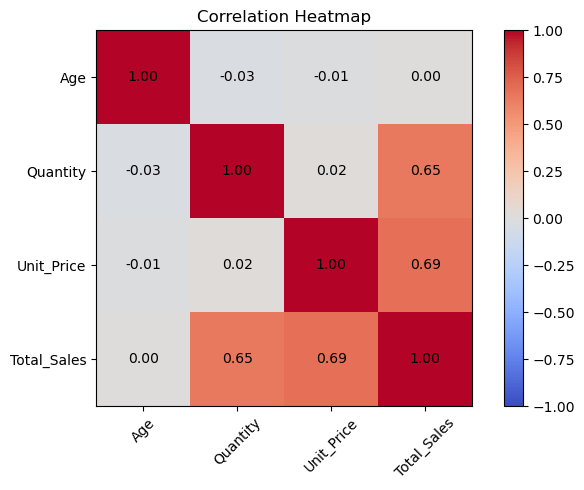

In [49]:
# Create the correlation heatmap
# Set the chart size
plt.figure(figsize=(7, 5))

# Display the correlation matrix as a colour map
plt.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)

# Add a colour scale
plt.colorbar()

# Add column names to the horizontal and vertical axes
plt.xticks(range(len(correlation.columns)), correlation.columns, rotation=45)
plt.yticks(range(len(correlation.columns)), correlation.columns)

# Display the exact correlation value inside each box
for i in range(len(correlation.columns)):
    for j in range(len(correlation.columns)):
        plt.text(
            j, i,
            f"{correlation.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

# Add title and adjust spacing
plt.title("Correlation Heatmap")
plt.tight_layout()

# Display the heatmap
plt.show()

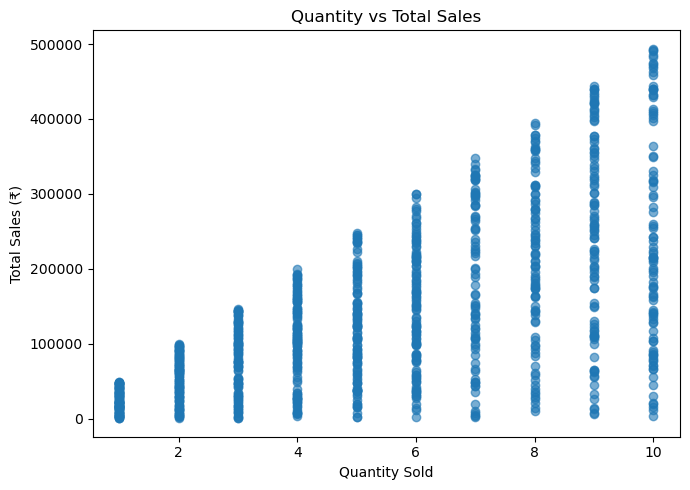

In [50]:
# Scatter plot 1: Quantity vs Total Sales
# Create the chart
plt.figure(figsize=(7, 5))

# Plot Quantity against Total_Sales
plt.scatter(df["Quantity"], df["Total_Sales"], alpha=0.6)

# Add labels and title
plt.xlabel("Quantity Sold")
plt.ylabel("Total Sales (₹)")
plt.title("Quantity vs Total Sales")

# Display the chart
plt.tight_layout()
plt.show()

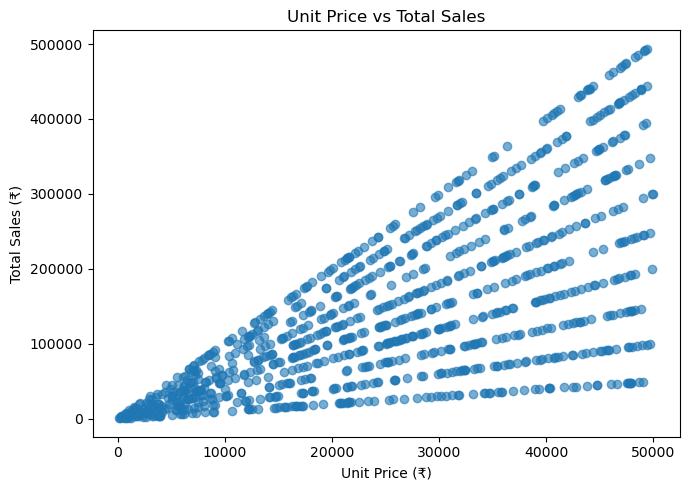

In [51]:
# Scatter plot 2 — Unit Price vs Total Sales
# Create the chart
plt.figure(figsize=(7, 5))

# Plot Unit_Price against Total_Sales
plt.scatter(df["Unit_Price"], df["Total_Sales"], alpha=0.6)

# Add labels and title
plt.xlabel("Unit Price (₹)")
plt.ylabel("Total Sales (₹)")
plt.title("Unit Price vs Total Sales")

# Display the chart
plt.tight_layout()
plt.show()

In [52]:
# Create the static sales dashboard
# Calculate important business KPIs
total_revenue = df["Total_Sales"].sum()
average_sales = df["Total_Sales"].mean()
total_records = len(df)

top_product = (
    df.groupby("Product")["Quantity"]
    .sum()
    .idxmax()
)

top_city = (
    df.groupby("City")["Total_Sales"]
    .sum()
    .drop("Unknown", errors="ignore")
    .idxmax()
)

top_category = (
    df.groupby("Category")["Total_Sales"]
    .sum()
    .idxmax()
)

# Display the KPIs
print("Total Revenue: ₹{:,.2f}".format(total_revenue))
print("Average Sales per Record: ₹{:,.2f}".format(average_sales))
print("Total Records:", total_records)
print("Top Selling Product:", top_product)
print("Top Revenue City:", top_city)
print("Top Revenue Category:", top_category)

Total Revenue: ₹139,399,439.65
Average Sales per Record: ₹139,399.44
Total Records: 1000
Top Selling Product: Mobile
Top Revenue City: Patna
Top Revenue Category: Electronics


In [53]:
# Convert Order_Date into datetime
# Convert Order_Date column into datetime format
df["Order_Date"] = pd.to_datetime(
    df["Order_Date"],
    format="%Y-%m-%d",
    errors="coerce"
)

# Check the data type
print(df["Order_Date"].dtype)

datetime64[ns]


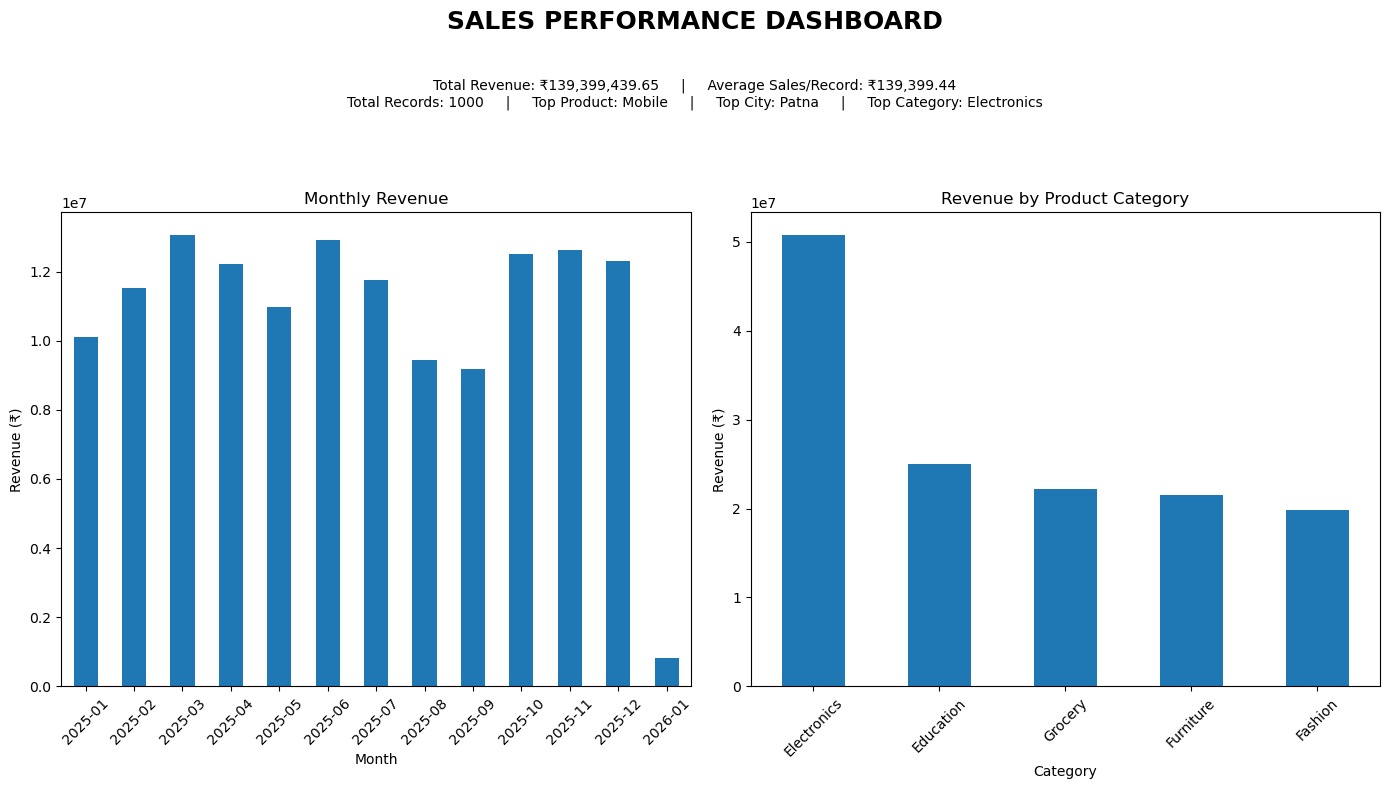

In [54]:
# Create your static sales dashboard
# We'll create a single dashboard containing:
# - Important business KPIs
# - Monthly revenue chart
# - Revenue by product category chart
# Calculate monthly revenue
monthly_sales = (
    df.groupby(df["Order_Date"].dt.to_period("M"))["Total_Sales"]
    .sum()
)

# Calculate revenue by category
category_sales = (
    df.groupby("Category")["Total_Sales"]
    .sum()
    .sort_values(ascending=False)
)

# Create dashboard layout
fig, axes = plt.subplots(1, 2, figsize=(14, 8))

# Main dashboard title
fig.suptitle(
    "SALES PERFORMANCE DASHBOARD",
    fontsize=18,
    fontweight="bold"
)

# Display KPI information
kpi_text = (
    f"Total Revenue: ₹{total_revenue:,.2f}     |     "
    f"Average Sales/Record: ₹{average_sales:,.2f}\n"
    f"Total Records: {total_records}     |     "
    f"Top Product: {top_product}     |     "
    f"Top City: {top_city}     |     "
    f"Top Category: {top_category}"
)

fig.text(0.5, 0.86, kpi_text, ha="center", fontsize=10)

# Monthly revenue chart
monthly_sales.plot(kind="bar", ax=axes[0])
axes[0].set_title("Monthly Revenue")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Revenue (₹)")
axes[0].tick_params(axis="x", rotation=45)

# Category revenue chart
category_sales.plot(kind="bar", ax=axes[1])
axes[1].set_title("Revenue by Product Category")
axes[1].set_xlabel("Category")
axes[1].set_ylabel("Revenue (₹)")
axes[1].tick_params(axis="x", rotation=45)

# Adjust dashboard spacing
plt.tight_layout(rect=[0, 0, 1, 0.82])

# Save dashboard as PNG
plt.savefig("Sales_Dashboard.png", dpi=300, bbox_inches="tight")

# Display dashboard
plt.show()

In [55]:
# Verify the saved file
import os

print("Dashboard file exists:", os.path.exists("Sales_Dashboard.png"))
print("File location:", os.path.abspath("Sales_Dashboard.png"))

Dashboard file exists: True
File location: C:\Users\gauri\apnacollege-demo\Apexplanetinternship\Task-2 EDA and Business intelligence\Sales_Dashboard.png
